# Tarea semanal — Búsqueda de raíces: sonda espacial (Newton-Raphson para sistemas)

**Fuente:** `Roots_searching.pdf`, sección *Tarea semanal*.

Dos estaciones terrestres rastrean una sonda en un plano (megámetros):
- Estación 1 en $(x_1, y_1) = (0, 0)$ Mm, con distancia medida $d_1 = 30$ Mm
- Estación 2 en $(x_2, y_2) = (50, 0)$ Mm, con distancia medida $d_2 = 40$ Mm

$$f_1(x,y) = (x-x_1)^2 + (y-y_1)^2 - d_1^2 = 0$$
$$f_2(x,y) = (x-x_2)^2 + (y-y_2)^2 - d_2^2 = 0$$

**Pedido:** encontrar $(x, y)$ con **Newton-Raphson para sistemas no lineales**, partiendo de
$(x_0, y_0) = (20, 20)$ Mm, con **al menos tres iteraciones**.

## Solución exacta (para verificar)

Restando ambas ecuaciones: $x^2 - (x-50)^2 = d_1^2 - d_2^2 \Rightarrow 100x - 2500 = -700 \Rightarrow x = 18$.
Luego $y^2 = d_1^2 - x^2 = 900 - 324 = 576 \Rightarrow y = \pm 24$. La semilla $(20,20)$ converge
a la rama superior: $(18, 24)$ Mm.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

x1, y1, d1 = 0.0, 0.0, 30.0
x2, y2, d2 = 50.0, 0.0, 40.0

def F(v):
    x, y = v
    return np.array([(x - x1)**2 + (y - y1)**2 - d1**2,
                     (x - x2)**2 + (y - y2)**2 - d2**2])

def J(v):
    # jacobiano
    x, y = v
    return np.array([[2*(x - x1), 2*(y - y1)],
                     [2*(x - x2), 2*(y - y2)]])

def newton_raphson_sistema(v0, n_iter):
    # NR para sistemas, v <- v - J⁻¹F
    v = np.array(v0, dtype=float)
    tray = [v.copy()]
    for k in range(n_iter):
        dv = np.linalg.solve(J(v), -F(v))
        v = v + dv
        tray.append(v.copy())
    return v, np.array(tray)

v_exacto = np.array([18.0, 24.0])
v_final, tray = newton_raphson_sistema((20.0, 20.0), n_iter=5)

print(f"{'k':>3} {'x [Mm]':>16} {'y [Mm]':>16} {'|Δv| [Mm]':>14} {'|v - exacto|':>14}")
print("-" * 67)
print(f"{0:>3} {tray[0,0]:>16.10f} {tray[0,1]:>16.10f} {'—':>14} {np.linalg.norm(tray[0]-v_exacto):>14.3e}")
for k in range(1, len(tray)):
    dv = np.linalg.norm(tray[k] - tray[k-1])
    print(f"{k:>3} {tray[k,0]:>16.10f} {tray[k,1]:>16.10f} {dv:>14.3e} {np.linalg.norm(tray[k]-v_exacto):>14.3e}")

print("-" * 67)
print(f"\nSolución: (x, y) = ({v_final[0]:.8f}, {v_final[1]:.8f}) Mm   (exacto: (18, 24) Mm)")
print(f"Con 3 iteraciones ya se tenía ({tray[3,0]:.6f}, {tray[3,1]:.6f}) Mm -> error "
      f"{np.linalg.norm(tray[3]-v_exacto):.2e} Mm (se cumple el 'al menos 3 iteraciones')")

  k           x [Mm]           y [Mm]      |Δv| [Mm]   |v - exacto|
-------------------------------------------------------------------
  0    20.0000000000    20.0000000000              —      4.472e+00
  1    18.0000000000    24.5000000000      4.924e+00      5.000e-01
  2    18.0000000000    24.0051020408      4.949e-01      5.102e-03
  3    18.0000000000    24.0000005422      5.101e-03      5.422e-07
  4    18.0000000000    24.0000000000      5.422e-07      7.105e-15
  5    18.0000000000    24.0000000000      7.105e-15      0.000e+00
-------------------------------------------------------------------

Solución: (x, y) = (18.00000000, 24.00000000) Mm   (exacto: (18, 24) Mm)
Con 3 iteraciones ya se tenía (18.000000, 24.000001) Mm -> error 5.42e-07 Mm (se cumple el 'al menos 3 iteraciones')


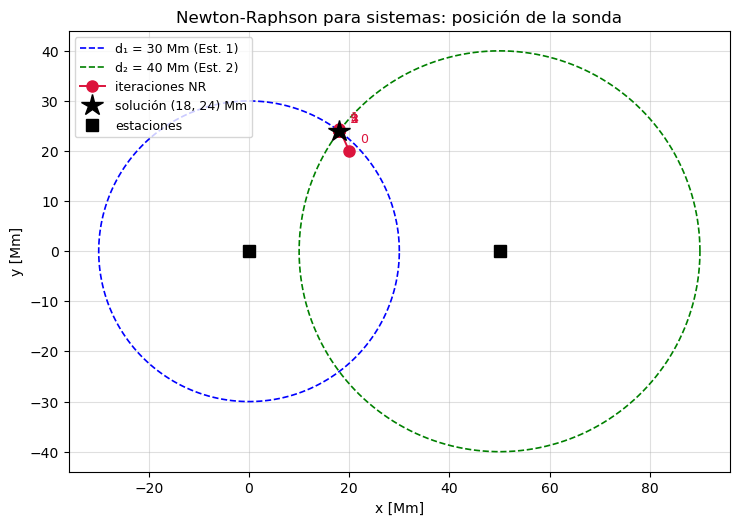

La convergencia es cuadrática: |Δv| pasa de ~2·10¹ a ~10⁻¹ y luego a ~10⁻⁴, ~10⁻⁸, ...
La intersección (18, -24) Mm también resuelve el sistema; la semilla (20, 20) selecciona la rama y > 0.


In [2]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
th = np.linspace(0, 2*np.pi, 400)
ax.plot(x1 + d1*np.cos(th), y1 + d1*np.sin(th), 'b--', lw=1.2, label='d₁ = 30 Mm (Est. 1)')
ax.plot(x2 + d2*np.cos(th), y2 + d2*np.sin(th), 'g--', lw=1.2, label='d₂ = 40 Mm (Est. 2)')
ax.plot(*tray.T, 'o-', color='crimson', lw=1.4, ms=8, label='iteraciones NR')
ax.plot(18, 24, 'k*', ms=16, label='solución (18, 24) Mm')
ax.plot([x1, x2], [y1, y2], 'ks', ms=9, label='estaciones')
for k, (xa, ya) in enumerate(tray):
    ax.annotate(f'{k}', (xa, ya), textcoords='offset points', xytext=(8, 6), fontsize=9, color='crimson')
ax.set_xlabel('x [Mm]'); ax.set_ylabel('y [Mm]')
ax.set_title('Newton-Raphson para sistemas: posición de la sonda')
ax.set_aspect('equal'); ax.grid(alpha=0.4); ax.legend(fontsize=9, loc='upper left')
plt.tight_layout(); plt.show()

print("La convergencia es cuadrática: |Δv| pasa de ~2·10¹ a ~10⁻¹ y luego a ~10⁻⁴, ~10⁻⁸, ...")
print("La intersección (18, -24) Mm también resuelve el sistema; la semilla (20, 20) selecciona la rama y > 0.")